# TP2 : Amélioration du moteur de recherche d'images (CBIR)
## Approche classique - Descripteurs globaux

**Réalisé par :** Melki Meriem
**Classe :** RT5 - Groupe 2

Dans ce TP on reprend le système CBIR du TP1 et on l'améliore en suivant les pistes proposées :
1. Changer l'espace de représentation de la couleur (RGB, HSV, Lab).
2. Utiliser d'autres distances que la distance euclidienne pour comparer les histogrammes.
3. Utiliser un descripteur de texture fréquentiel : les filtres de Gabor.
4. Ajouter un autre descripteur de forme : l'histogramme des orientations des contours (EOH).
5. Combiner les descripteurs avec des poids.
6. Créer une petite interface graphique pour choisir l'image requête et afficher les résultats.

On utilise la même base que le TP1 (dossiers `obj_decoys` et `img_requetes`).

## Importation des bibliothèques et lecture de la base

In [3]:
import os
import glob
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.feature import hog

In [4]:
# Sur Kaggle la base est dans /kaggle/input/<nom_du_dataset>/...
# on cherche directement les deux dossiers obj_decoys et img_requetes
EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp')

def lister_images(dossier):
    return sorted([f for f in os.listdir(dossier) if f.lower().endswith(EXTENSIONS)])

def chercher_dossier(nom):
    for d in glob.glob('/kaggle/input/**/' + nom, recursive=True):
        if os.path.isdir(d) and len(lister_images(d)) > 0:
            return d
    raise FileNotFoundError("Dossier introuvable : " + nom)

dossier_base = chercher_dossier('obj_decoys')
dossier_req = chercher_dossier('img_requetes')
print("Base :", dossier_base)
print("Requetes :", dossier_req)

Base : /kaggle/input/datasets/melkimariem/cbir-dataset/CBIR_DataSet/obj_decoys
Requetes : /kaggle/input/datasets/melkimariem/cbir-dataset/CBIR_DataSet/img_requetes


In [5]:
def lire_image(chemin):
    img = cv2.imread(chemin)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # OpenCV lit en BGR

noms_images = lister_images(dossier_base)
base = {nom: lire_image(os.path.join(dossier_base, nom)) for nom in noms_images}
print("Nombre d'images dans la base :", len(base))

noms_req = lister_images(dossier_req)
requetes = [lire_image(os.path.join(dossier_req, nom)) for nom in noms_req]
print("Images requetes :", noms_req)

Nombre d'images dans la base : 270
Images requetes : ['ImageRequete.jpg', 'ImageRequete2.jpg']


In [6]:
def afficher_resultats(img_req, resultats, titre=""):
    # affiche l'image requete puis les images trouvees avec leur distance
    n = len(resultats)
    plt.figure(figsize=(3 * (n + 1), 3))
    plt.subplot(1, n + 1, 1)
    plt.imshow(img_req)
    plt.title("Requete")
    plt.axis('off')
    for i, (nom, d) in enumerate(resultats):
        plt.subplot(1, n + 1, i + 2)
        plt.imshow(base[nom])
        plt.title(f"{nom}\nd = {d:.3f}", fontsize=9)
        plt.axis('off')
    plt.suptitle(titre)
    plt.tight_layout()
    plt.show()

Fonctions communes reprises du TP1 : indexation de la base pour une fonction de descripteur donnée, et recherche avec une fonction de distance au choix. Pour la distance euclidienne on normalise les composantes (centrer-réduire) comme dans le TP1.

In [7]:
def indexer(fonction_descripteur):
    return np.array([fonction_descripteur(base[nom]) for nom in noms_images])

def distance_euclidienne(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def rechercher(img_req, ind_Matrix, fonction_descripteur, distance=distance_euclidienne,
               normaliser=True, nb=5):
    q = fonction_descripteur(img_req)
    M = ind_Matrix
    if normaliser:
        moy = M.mean(axis=0)
        ecart = M.std(axis=0) + 1e-10
        M = (M - moy) / ecart
        q = (q - moy) / ecart
    distances = {noms_images[i]: distance(q, M[i]) for i in range(len(noms_images))}
    distances = sorted(distances.items(), key=lambda x: x[1])
    return distances[:nb]

## 1. Espaces de représentation de la couleur
Dans le TP1, les moments de couleur étaient calculés dans l'espace RGB. Les trois composantes RGB sont corrélées et sensibles à l'éclairage. On compare ici avec :
- **HSV** : sépare la teinte (H), la saturation (S) et la luminosité (V).
- **Lab** : L pour la luminance, a et b pour la chrominance. C'est un espace presque uniforme du point de vue perceptuel.

Pour chaque composante on calcule la moyenne, l'écart type et le coefficient d'asymétrie (moment d'ordre 3 vu en cours), soit 9 valeurs.

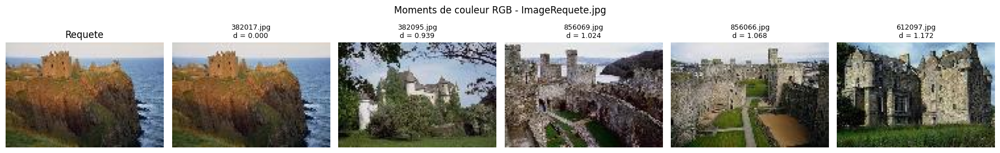

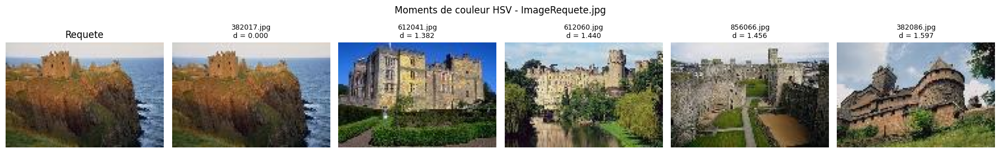

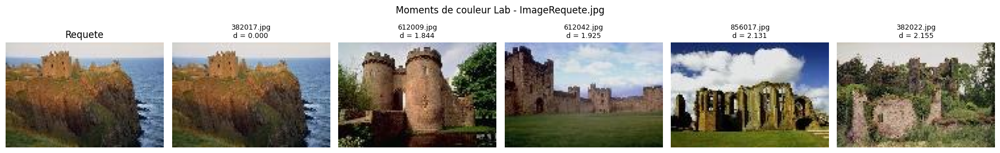

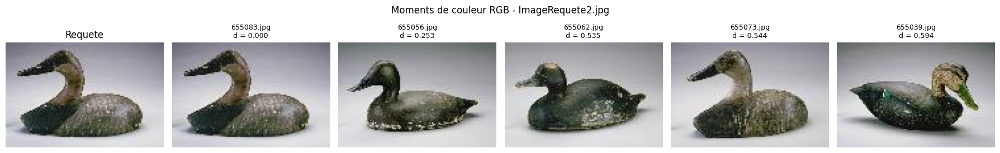

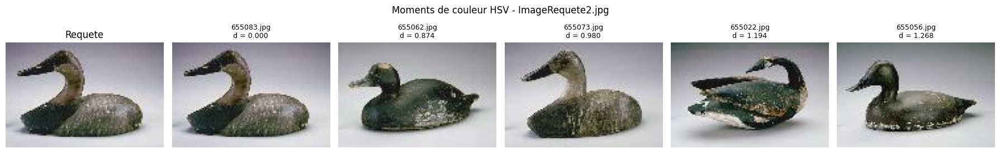

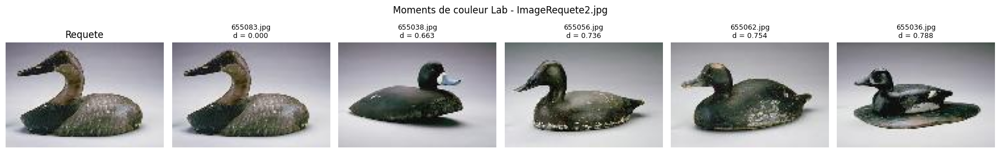

In [8]:
def color_Moments_espace(img, espace='RGB'):
    if espace == 'HSV':
        img = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    elif espace == 'Lab':
        img = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    img = img.astype(float)
    features = []
    for k in range(3):
        canal = img[:, :, k]
        moy = canal.mean()
        ecart = canal.std()
        asym = np.mean((canal - moy) ** 3) / (ecart ** 3 + 1e-10)
        features += [moy, ecart, asym]
    return np.array(features)

espaces = ['RGB', 'HSV', 'Lab']
index_couleur = {e: indexer(lambda im, e=e: color_Moments_espace(im, e)) for e in espaces}

for i, img in enumerate(requetes):
    for e in espaces:
        res = rechercher(img, index_couleur[e], lambda im, e=e: color_Moments_espace(im, e))
        afficher_resultats(img, res, "Moments de couleur " + e + " - " + noms_req[i])

**Interprétation :**
Pour les deux requêtes, les trois espaces donnent des images du bon groupe (5 châteaux et 5 canards). Avec 9 moments au lieu de 6, le château blanc qui apparaissait au TP1 pour la requête 2 n'est plus là. Les images trouvées changent selon l'espace : en Lab, on obtient pour la requête 1 des châteaux en pierre brune ou rouge, plus proches des couleurs de la requête. HSV et Lab séparent la luminosité de la couleur, ce qui donne des résultats plus proches de ce que l'oeil perçoit.

## 2. Distances pour la comparaison d'histogrammes
La distance euclidienne n'est pas la mieux adaptée aux histogrammes car elle compare les cases une par une sans tenir compte de leur nature de distribution. On compare sur l'histogramme HSV (8x4x4 = 128 cases, normalisé) les distances suivantes :

- **Euclidienne** : $d(H_1,H_2) = \sqrt{\sum_i (H_1(i) - H_2(i))^2}$
- **Intersection d'histogrammes** : $d = 1 - \sum_i \min(H_1(i), H_2(i))$
- **Khi-deux** : $d = \frac{1}{2}\sum_i \frac{(H_1(i) - H_2(i))^2}{H_1(i) + H_2(i)}$
- **Bhattacharyya** : $d = \sqrt{1 - \sum_i \sqrt{H_1(i) H_2(i)}}$

Les histogrammes sont déjà normalisés, on ne fait donc pas la normalisation centrer-réduire ici.

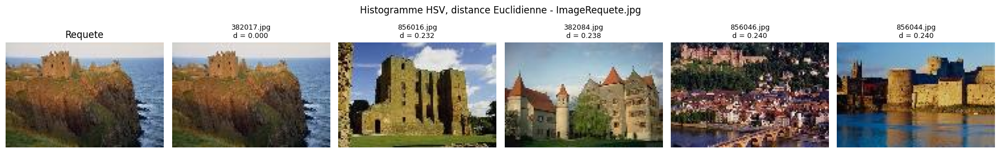

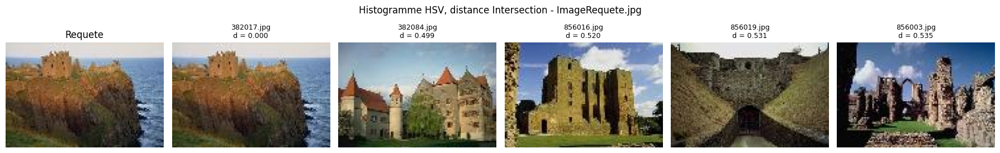

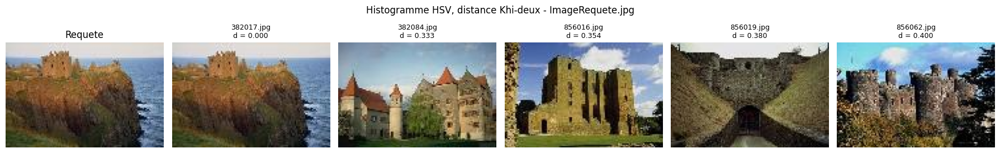

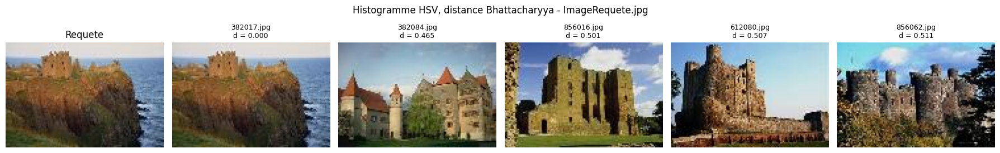

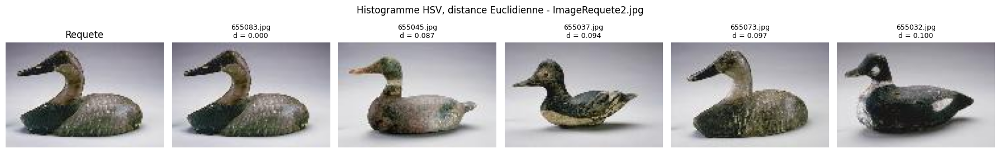

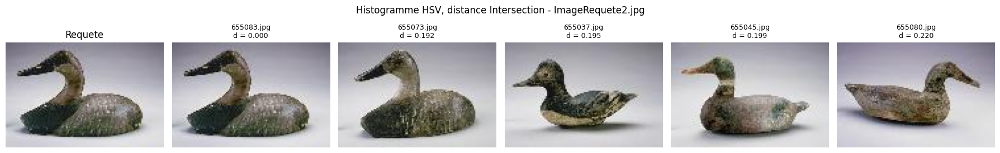

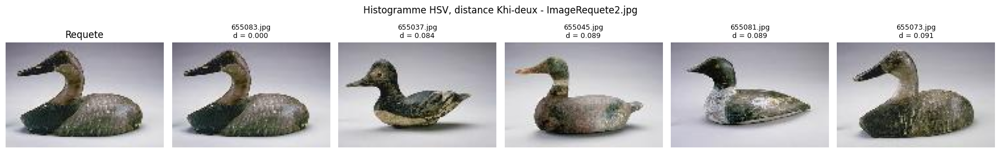

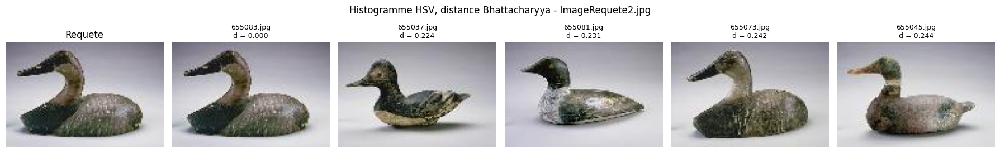

In [9]:
def hsvHistogramFeatures(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    hist = cv2.calcHist([hsv], [0, 1, 2], None, [8, 4, 4], [0, 180, 0, 256, 0, 256])
    hist = hist.flatten()
    return hist / hist.sum()

def d_intersection(h1, h2):
    return 1 - np.sum(np.minimum(h1, h2))

def d_chi2(h1, h2):
    return 0.5 * np.sum((h1 - h2) ** 2 / (h1 + h2 + 1e-10))

def d_bhattacharyya(h1, h2):
    return np.sqrt(max(0, 1 - np.sum(np.sqrt(h1 * h2))))

distances = {
    'Euclidienne': distance_euclidienne,
    'Intersection': d_intersection,
    'Khi-deux': d_chi2,
    'Bhattacharyya': d_bhattacharyya,
}

index_hist = indexer(hsvHistogramFeatures)

for i, img in enumerate(requetes):
    for nom_d, fd in distances.items():
        res = rechercher(img, index_hist, hsvHistogramFeatures, distance=fd, normaliser=False)
        afficher_resultats(img, res, "Histogramme HSV, distance " + nom_d + " - " + noms_req[i])

**Interprétation :**
Toutes les distances retrouvent le bon groupe. La différence est dans l'ordre. Avec la distance euclidienne, on a pour la requête 1 une vue de ville (856046.jpg) assez différente de la requête. L'intersection, le Khi-deux et Bhattacharyya donnent des résultats très proches entre eux (382084.jpg et 856016.jpg en tête pour la requête 1, 655037.jpg et 655073.jpg pour la requête 2). Ces distances sont faites pour comparer des distributions, elles sont donc mieux adaptées aux histogrammes.

## 3. Descripteur de texture de Gabor
Un filtre de Gabor est le produit d'une sinusoïde orientée et d'une gaussienne. On utilise une banque de filtres : 3 longueurs d'onde (4, 8 et 16 pixels) et 4 orientations (0°, 45°, 90°, 135°), donc 12 filtres. Pour chaque réponse filtrée on garde l'énergie moyenne et la variance, ce qui donne un vecteur de 24 valeurs. On le compare au descripteur GLCM du TP1.

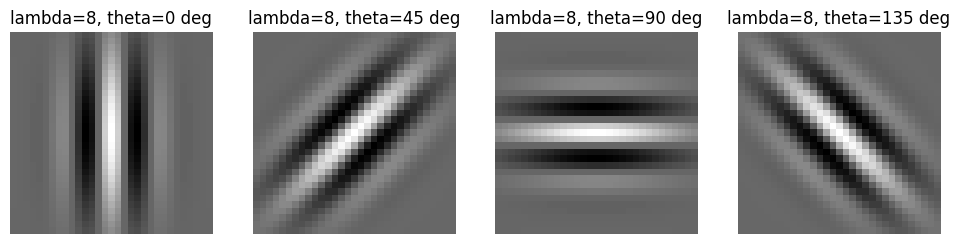

In [10]:
from skimage.feature import graycomatrix, graycoprops

def textureFeatures(img):    # GLCM du TP1
    gris = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    gris = (gris // 8).astype(np.uint8)
    glcm = graycomatrix(gris, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                        levels=32, symmetric=True, normed=True)
    proprietes = ['contrast', 'correlation', 'energy', 'homogeneity']
    return np.array([graycoprops(glcm, p).mean() for p in proprietes])

# banque de filtres de Gabor creee une seule fois
filtres_gabor = []
for lambd in [4, 8, 16]:
    for theta in [0, np.pi/4, np.pi/2, 3*np.pi/4]:
        k = cv2.getGaborKernel((31, 31), sigma=0.56 * lambd, theta=theta,
                               lambd=lambd, gamma=0.5, psi=0)
        filtres_gabor.append(k)

def gaborFeatures(img):
    gris = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    gris = cv2.resize(gris, (128, 128)).astype(np.float32) / 255
    features = []
    for k in filtres_gabor:
        rep = cv2.filter2D(gris, cv2.CV_32F, k)
        features.append(np.mean(np.abs(rep)))
        features.append(np.var(rep))
    return np.array(features)

# affichage de quelques filtres
plt.figure(figsize=(12, 3))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(filtres_gabor[4 + i], cmap='gray')
    plt.title(f"lambda=8, theta={45 * i} deg")
    plt.axis('off')
plt.show()

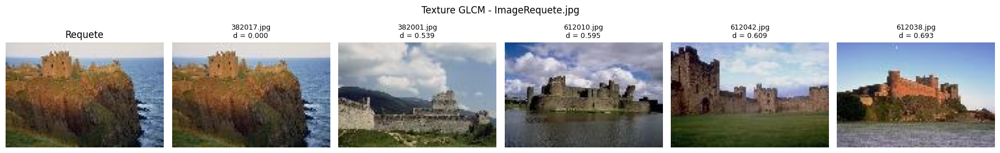

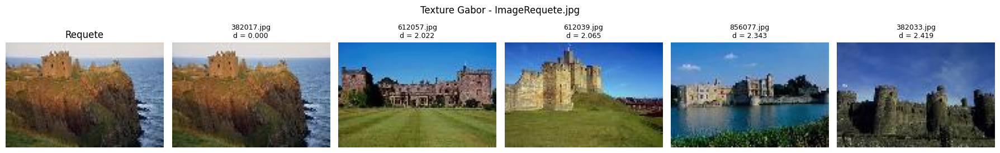

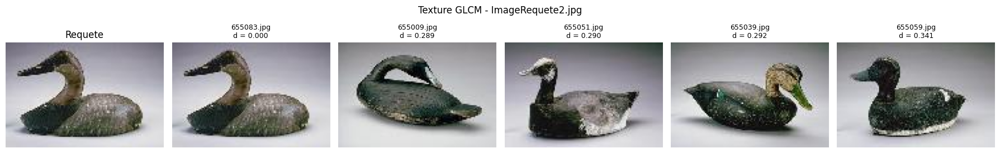

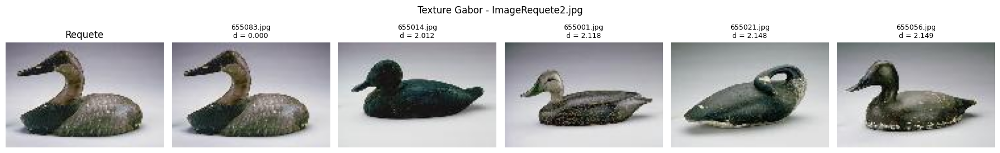

In [11]:
index_glcm = indexer(textureFeatures)
index_gabor = indexer(gaborFeatures)

for i, img in enumerate(requetes):
    afficher_resultats(img, rechercher(img, index_glcm, textureFeatures), "Texture GLCM - " + noms_req[i])
    afficher_resultats(img, rechercher(img, index_gabor, gaborFeatures), "Texture Gabor - " + noms_req[i])

**Interprétation :**
Les deux descripteurs retrouvent le bon groupe pour les deux requêtes, car les textures des deux groupes sont très différentes (fond gris uniforme pour les canards, scènes naturelles pour les châteaux). Avec Gabor, on obtient pour la requête 1 des châteaux avec de grandes zones homogènes (ciel, pelouse, eau), et pour la requête 2 des canards foncés à surface lisse. Gabor donne une description plus riche (24 valeurs, plusieurs échelles et orientations) que la GLCM (4 valeurs).

## 4. Descripteur de forme : histogramme des orientations des contours (EOH)
Comme vu en cours, l'EOH est calculé de la façon suivante :
- calcul des gradients horizontal Gx et vertical Gy (filtres de Sobel),
- on garde seulement les pixels de contour (module du gradient supérieur à la moyenne),
- l'orientation est quantifiée sur 4 angles : 0°, 45°, 90° et 135°,
- l'image est divisée en 16 blocs (4x4) et on calcule un histogramme de 4 orientations par bloc.

Le vecteur obtenu a 16 x 4 = 64 valeurs, beaucoup moins que le HOG du TP1 (1568).

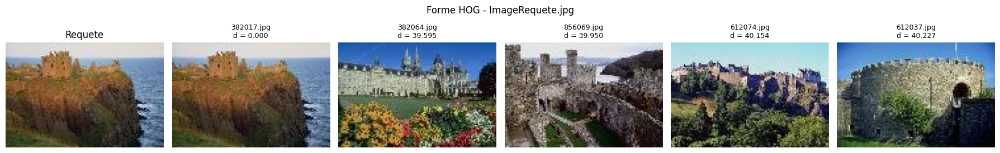

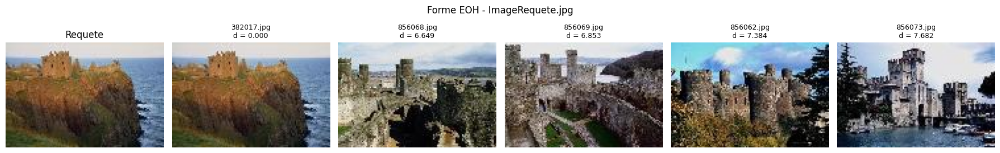

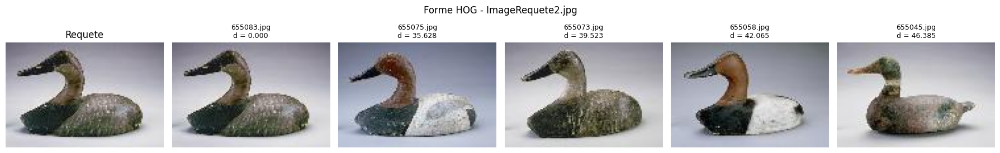

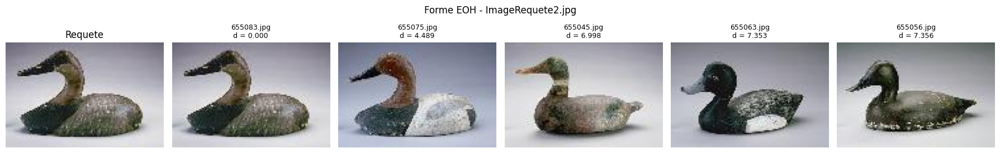

In [12]:
def shapeFeaturesHOG(img):   # HOG du TP1
    gris = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    gris = cv2.resize(gris, (64, 64))
    return hog(gris, orientations=8, pixels_per_cell=(8, 8),
               cells_per_block=(2, 2), block_norm='L2-Hys')

def eohFeatures(img):
    gris = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    gris = cv2.resize(gris, (128, 128)).astype(np.float32)
    gx = cv2.Sobel(gris, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(gris, cv2.CV_32F, 0, 1)
    module = np.sqrt(gx ** 2 + gy ** 2)
    angle = np.degrees(np.arctan2(gy, gx)) % 180
    orientation = np.round(angle / 45).astype(int) % 4   # 0, 45, 90, 135
    contour = module > module.mean()
    features = []
    for i in range(4):
        for j in range(4):
            o = orientation[i*32:(i+1)*32, j*32:(j+1)*32]
            ct = contour[i*32:(i+1)*32, j*32:(j+1)*32]
            h = np.bincount(o[ct], minlength=4).astype(float)
            features.extend(h / (h.sum() + 1e-10))
    return np.array(features)

index_hog = indexer(shapeFeaturesHOG)
index_eoh = indexer(eohFeatures)

for i, img in enumerate(requetes):
    afficher_resultats(img, rechercher(img, index_hog, shapeFeaturesHOG), "Forme HOG - " + noms_req[i])
    afficher_resultats(img, rechercher(img, index_eoh, eohFeatures), "Forme EOH - " + noms_req[i])

**Interprétation :**
Pour la requête 2, les deux descripteurs retrouvent des canards de même silhouette, et 655075.jpg est en 2e position dans les deux cas. Pour la requête 1, l'EOH retourne des châteaux avec beaucoup de contours verticaux (tours, ruines). L'EOH donne des résultats comparables au HOG avec seulement 64 valeurs au lieu de 1568, donc une recherche plus rapide.

## 5. Combinaison pondérée des descripteurs
Dans le TP1 on avait concaténé tous les descripteurs dans un seul vecteur. Le problème est que le HOG (1568 valeurs) écrasait les autres. Ici on calcule une distance pour chaque descripteur séparément, on la divise par sa valeur maximale sur la base (pour la ramener entre 0 et 1), puis on fait une somme pondérée :

$$D = w_1 d_{couleur} + w_2 d_{histogramme} + w_3 d_{texture} + w_4 d_{forme}$$

Descripteurs retenus : moments de couleur en HSV, histogramme HSV avec la distance de Bhattacharyya, texture de Gabor et forme EOH. Les poids permettent de choisir l'importance de chaque caractéristique.

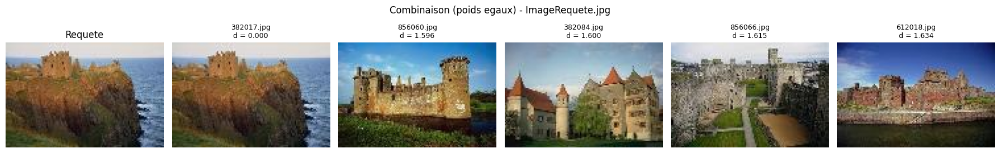

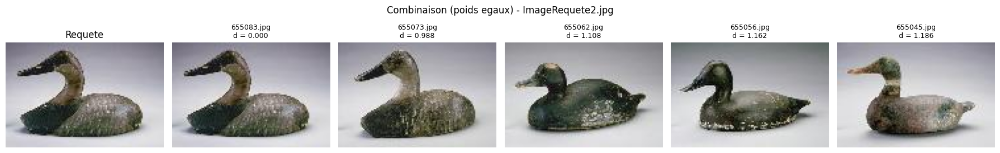

In [13]:
descripteurs = {
    'couleur': lambda im: color_Moments_espace(im, 'HSV'),
    'histogramme': hsvHistogramFeatures,
    'texture': gaborFeatures,
    'forme': eohFeatures,
}

index = {
    'couleur': index_couleur['HSV'],
    'histogramme': index_hist,
    'texture': index_gabor,
    'forme': index_eoh,
}

def distances_descripteur(img_req, nom):
    q = descripteurs[nom](img_req)
    M = index[nom]
    if nom == 'histogramme':
        d = np.array([d_bhattacharyya(q, m) for m in M])
    else:
        moy = M.mean(axis=0)
        ecart = M.std(axis=0) + 1e-10
        d = np.array([distance_euclidienne((q - moy) / ecart, (m - moy) / ecart) for m in M])
    return d / (d.max() + 1e-10)

def recherche_combinee(img_req, poids, nb=5):
    total = np.zeros(len(noms_images))
    for nom, w in poids.items():
        if w > 0:
            total += w * distances_descripteur(img_req, nom)
    ordre = np.argsort(total)[:nb]
    return [(noms_images[i], total[i]) for i in ordre]

poids = {'couleur': 1, 'histogramme': 1, 'texture': 1, 'forme': 1}
for i, img in enumerate(requetes):
    afficher_resultats(img, recherche_combinee(img, poids), "Combinaison (poids egaux) - " + noms_req[i])

**Interprétation :**
La combinaison donne de bons résultats pour les deux requêtes : 5 châteaux pour la requête 1 et 5 canards pour la requête 2. Les images trouvées ressemblent à la requête à la fois en couleur et en forme (par exemple 655073.jpg pour la requête 2). Aucun descripteur ne domine les autres, contrairement au TP1 où le HOG écrasait la couleur. Quand on donne plus de poids à la forme, des châteaux en ruines (856066.jpg, 856068.jpg) montent dans le classement.

## 6. Interface graphique
On utilise `ipywidgets` pour créer une interface simple dans le notebook :
- choix d'une image requête parmi celles du dossier `img_requetes`, ou chargement d'une image depuis l'ordinateur,
- réglage des poids de chaque descripteur,
- bouton pour lancer la recherche et affichage des 5 images les plus similaires.

In [14]:
import ipywidgets as widgets
from IPython.display import display, clear_output

choix_req = widgets.Dropdown(options=noms_req, description='Requete :')
upload = widgets.FileUpload(accept='image/*', multiple=False, description='Charger')
s_couleur = widgets.FloatSlider(value=1, min=0, max=2, step=0.1, description='Couleur')
s_hist = widgets.FloatSlider(value=1, min=0, max=2, step=0.1, description='Histogramme')
s_texture = widgets.FloatSlider(value=1, min=0, max=2, step=0.1, description='Texture')
s_forme = widgets.FloatSlider(value=1, min=0, max=2, step=0.1, description='Forme')
s_nb = widgets.IntSlider(value=5, min=1, max=10, description='Nb images')
bouton = widgets.Button(description='Rechercher', button_style='primary')
sortie = widgets.Output()

def image_requete():
    # si une image a ete chargee on l'utilise, sinon celle de la liste
    v = upload.value
    if len(v) > 0:
        fichier = list(v.values())[0] if isinstance(v, dict) else v[0]
        donnees = np.frombuffer(bytes(fichier['content']), np.uint8)
        img = cv2.imdecode(donnees, cv2.IMREAD_COLOR)
        return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return requetes[noms_req.index(choix_req.value)]

def lancer_recherche(b):
    with sortie:
        clear_output(wait=True)
        poids = {'couleur': s_couleur.value, 'histogramme': s_hist.value,
                 'texture': s_texture.value, 'forme': s_forme.value}
        if sum(poids.values()) == 0:
            print("Il faut au moins un poids non nul.")
            return
        img = image_requete()
        afficher_resultats(img, recherche_combinee(img, poids, s_nb.value), "Resultats de la recherche")

bouton.on_click(lancer_recherche)

display(widgets.VBox([
    widgets.HBox([choix_req, upload]),
    widgets.HBox([s_couleur, s_hist]),
    widgets.HBox([s_texture, s_forme]),
    widgets.HBox([s_nb, bouton]),
    sortie,
]))

Remarque : si les widgets ne s'affichent pas, on peut lancer la recherche directement avec la fonction `recherche_combinee`, par exemple en donnant plus de poids à la forme :

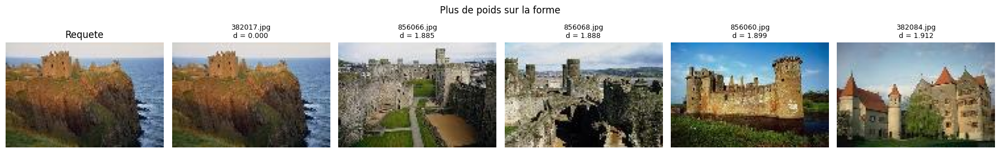

In [15]:
poids = {'couleur': 0.5, 'histogramme': 1, 'texture': 0.5, 'forme': 2}
afficher_resultats(requetes[0], recherche_combinee(requetes[0], poids), "Plus de poids sur la forme")

## Conclusion
Dans notre base, les deux groupes (châteaux et canards en bois) sont très différents, donc presque tous les descripteurs retrouvent le bon groupe. La différence se voit surtout dans la ressemblance des images trouvées :
- HSV et Lab donnent des couleurs plus proches que RGB.
- Les distances intersection, Khi-deux et Bhattacharyya sont mieux adaptées aux histogrammes que la distance euclidienne.
- Gabor décrit mieux la texture que la GLCM.
- L'EOH donne des résultats proches du HOG avec un vecteur beaucoup plus petit.
- La combinaison pondérée évite qu'un descripteur domine les autres.

La limite principale reste la rotation et le fossé sémantique : des descripteurs de bas niveau ne suffisent pas toujours à retrouver des images qui ont le même sens.